In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("Data/data.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_

In [4]:
print("Shape of dataset:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

Shape of dataset: (569, 33)

Column names:
Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='str')

Missing values:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0

In [5]:
# Remove unnecessary columns
df = df.drop(columns=["id", "Unnamed: 32"])

# Check target values
print("Diagnosis values:")
print(df["diagnosis"].value_counts())

print("\nDataset shape after cleaning:")
print(df.shape)

Diagnosis values:
diagnosis
B    357
M    212
Name: count, dtype: int64

Dataset shape after cleaning:
(569, 31)


In [6]:
df = df.drop(columns=["id", "Unnamed: 32"])

print("Diagnosis values:")
print(df["diagnosis"].value_counts())

print("\nDataset shape after cleaning:")
print(df.shape)

KeyError: "['id', 'Unnamed: 32'] not found in axis"

In [7]:
print("Diagnosis values:")
print(df["diagnosis"].value_counts())

print("\nDataset shape:")
print(df.shape)

Diagnosis values:
diagnosis
B    357
M    212
Name: count, dtype: int64

Dataset shape:
(569, 31)


In [8]:
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})

print(df["diagnosis"].value_counts())
print(df.head())

diagnosis
0    357
1    212
Name: count, dtype: int64
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38          122.80     1001.0   
1          1        20.57         17.77          132.90     1326.0   
2          1        19.69         21.25          130.00     1203.0   
3          1        11.42         20.38           77.58      386.1   
4          1        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_

In [9]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

Feature scaling completed!
X_train_scaled shape: (455, 30)
X_test_scaled shape: (114, 30)


In [12]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])
print("First 10 probabilities:", y_prob[:10])

Predictions completed!
First 10 predictions: [0 1 0 1 1 0 1 0 0 0]
First 10 probabilities: [3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [14]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[71  1]
 [ 3 39]]


In [15]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.9649122807017544
Accuracy (%): 96.49122807017544


In [16]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.975
Recall: 0.9285714285714286


In [17]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [18]:
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.996031746031746


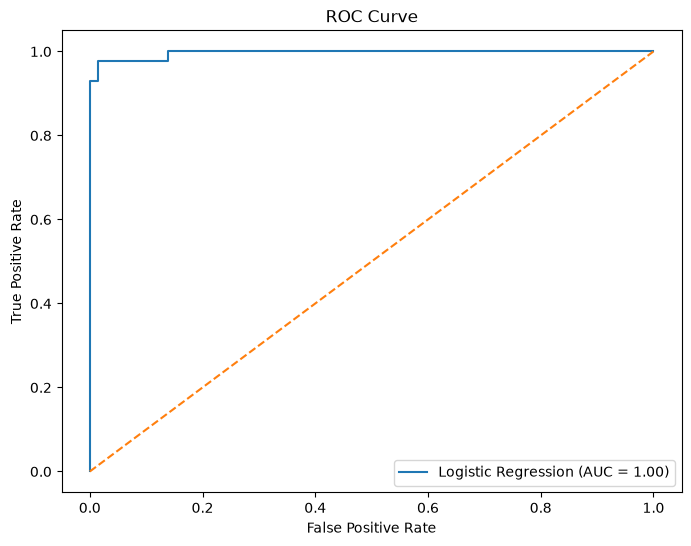

In [19]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

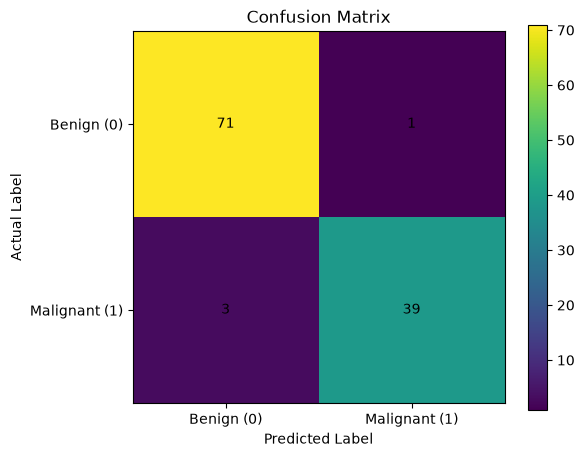

In [20]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.colorbar()

plt.xticks([0, 1], ["Benign (0)", "Malignant (1)"])
plt.yticks([0, 1], ["Benign (0)", "Malignant (1)"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [21]:
threshold = 0.5

y_pred_threshold = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Predictions with threshold:", y_pred_threshold[:10])

Threshold: 0.5
Predictions with threshold: [0 1 0 1 1 0 1 0 0 0]


In [23]:
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred_temp = (y_prob >= threshold).astype(int)
    precision = precision_score(y_test, y_pred_temp)
    recall = recall_score(y_test, y_pred_temp)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f}"
    )

Threshold: 0.3 | Precision: 0.976 | Recall: 0.976
Threshold: 0.4 | Precision: 0.976 | Recall: 0.952
Threshold: 0.5 | Precision: 0.975 | Recall: 0.929
Threshold: 0.6 | Precision: 1.000 | Recall: 0.905
Threshold: 0.7 | Precision: 1.000 | Recall: 0.905


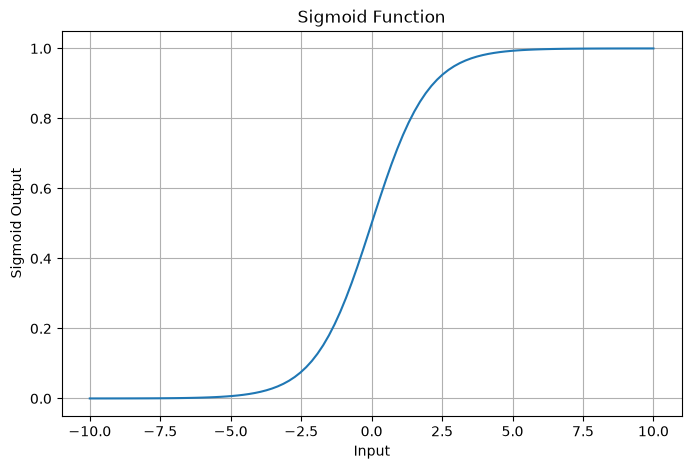

In [24]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

x = np.linspace(-10, 10, 100)

plt.figure(figsize=(8, 5))
plt.plot(x, sigmoid(x))

plt.xlabel("Input")
plt.ylabel("Sigmoid Output")
plt.title("Sigmoid Function")
plt.grid()
plt.show()

In [25]:
print("Final Model Performance")
print("-----------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

Final Model Performance
-----------------------
Accuracy  : 0.9649
Precision : 0.9750
Recall    : 0.9286
ROC-AUC   : 0.9960
